In [3]:
import numpy as np
from pathlib import Path
import pandas as pd
import sys
sys.path.insert(1, '../../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color,Radar
from util.overshoots import local_safety, critical_parameter, OS_model, k_risk

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

from matplotlib.colors import LinearSegmentedColormap
import colorcet as cc

from mpl_toolkits.basemap import Basemap
import networkx as nx

In [4]:
### PROVIDE scenarios 
# Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). 
    # Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. 
    # Zenodo. https://doi.org/10.5281/zenodo.11108741
# https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description
# https://zenodo.org/records/11108741 for actual data set

folder = '../../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

### GTPR 2025
df_TEs = pd.read_excel('../../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')

In [3]:
df_TEs.index.values

array(['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS',
       'WAM'], dtype=object)

In [4]:
### Pre-generated interaction matrices from GTPR2025
len_sample=500
A = [np.loadtxt('../../../Data/Interaction matrices/GTPR2025/A_%s.csv'%r) for r in range(len_sample)]

df_interactions = pd.read_excel('../../../Data/Interactions_TableA2.xlsx',usecols='A:F',header=[0],sheet_name='Interactions (GTPR25)')

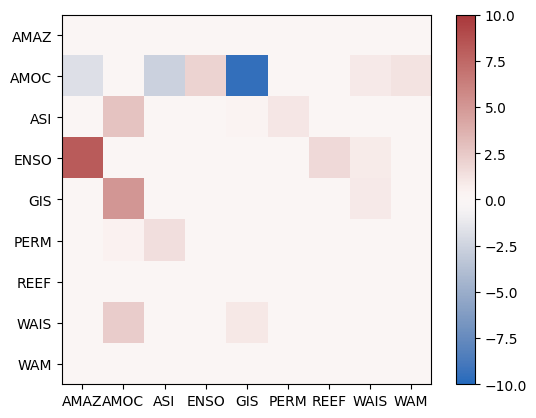

In [5]:
fig,ax=plt.subplots()
im=ax.imshow(A[100],vmin=-10,vmax=10,cmap='vlag')
ax.set_xticks(range(A[0].shape[0]), df_TEs.index.values)
ax.set_yticks(range(A[0].shape[0]), df_TEs.index.values)
plt.colorbar(im)

In [6]:
G = nx.from_pandas_edgelist(df_interactions,source='Source',target='Target',edge_attr=['min', 'max'],create_using=nx.DiGraph)
m = Basemap(projection='eck4',lon_0=-30,resolution='c',)
            # llcrnrlat=-80,urcrnrlat=80,llcrnrlon=-180,urcrnrlon=180,lat_ts=20,);
pos_lonlat = {'GIS':[-43,70], 'AMOC':[-30,43],'ENSO':[-130,-8.8],
              'WAIS':[-90,-75],'ASI':[5,70],'PERM':[100,60],
              'WAM':[14,19.5],'REEF':[-80,12],'AMAZ':[-62.2,-3.5]}
pos_xy ={k:m(v[0],v[1]) for k,v in pos_lonlat.items()}
T_lim_dic = df_TEs['Threshold (°C) – Est.'].to_dict()

In [7]:
elist = [(e[0],e[1],0) for e in G.edges]
earc_dic = {e:0 for e in G.edges}
earc_dic[('GIS','AMOC')]=0.2
earc_dic[('AMOC','GIS')]=0.2
earc_dic[('AMOC','WAIS')]=-0.5
earc_dic[('AMOC','ENSO')]=0.3
earc_dic[('WAIS','AMOC')]=0.3
earc_dic[('ASI','AMOC')]=0.15
earc_dic[('AMOC','ASI')]=0.15
earc_dic[('ASI','GIS')]=0.1
earc_dic[('PERM','AMOC')]=-0.15
earc_dic[('ASI','PERM')]=-0.1
earc_dic[('PERM','ASI')]=-0.1
earc_dic[('WAIS','GIS')]=-1.3
earc_dic[('GIS','WAIS')]=1.6

For automatic curved edges check out netgraph: \
https://stackoverflow.com/questions/52588453/drawing-curved-edges-with-networkx-in-python \
https://github.com/paulbrodersen/netgraph/tree/master

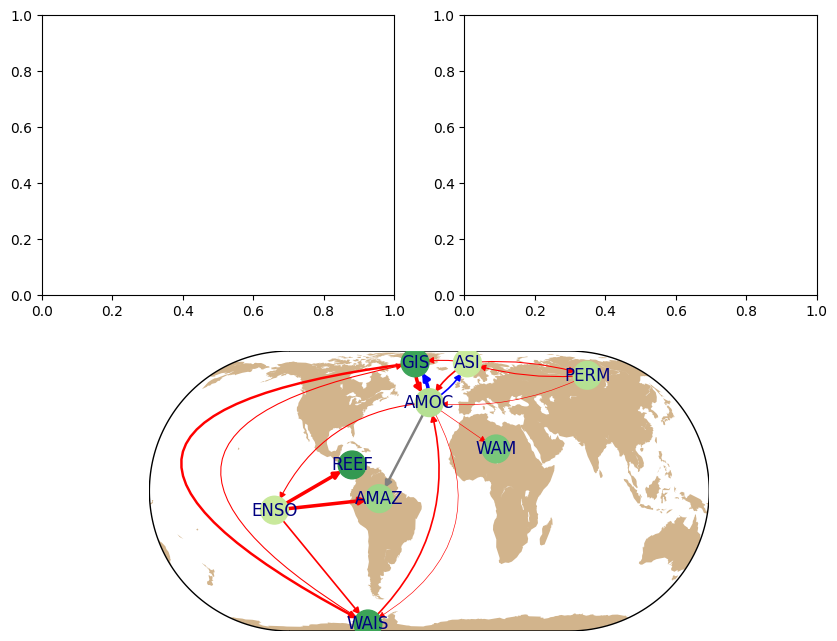

In [40]:
fig = plt.figure(figsize=(10,8))
ax1= fig.add_subplot(2,2,1)
ax2= fig.add_subplot(2,2,2)
ax3= fig.add_subplot(2,1,2)

m.fillcontinents(color='tan',lake_color='white',ax=ax3);
nx.draw_networkx(G,ax=ax3,pos=pos_xy,node_size=400,with_labels=True,edgelist=[],
                 node_color=[T_lim_dic[n] for n in G.nodes()],
                 vmin=-1.5,vmax=7,
                 cmap='YlGn_r',font_size=12,font_color='navy',font_weight=None)
for e in G.edges:
    vals = G.get_edge_data(e[0],e[1])
    if vals['min'] > 0: # Destabilising
        c = 'r'
        w = vals['max']
    elif vals['max'] < 0: # Stabilising
        c = 'b'
        w= np.abs(vals['min'])
    else: # Unclear
        c = 'gray' 
        w = vals['max']
    nx.draw_networkx_edges(G,pos_xy,ax=ax3,edgelist=[e], 
                           edge_color=c, width=np.log(w)*1.1,
                           connectionstyle="arc3,rad=rrr".replace('rrr',str(earc_dic[e])));
# m.drawcoastlines(ax=ax3)
# m.drawlsmask()

# Testing netgraph for visualisation

In [9]:
from netgraph import Graph

In [40]:
print(m(0,0))
print(m(-150,0))
print(m(210,0))

(19719303.91295753, 8451130.2484144)
(5634086.832266869, 8451130.2484144)
(5634086.832266871, 8451130.2484144)


TypeError: unsupported operand type(s) for -: 'tuple' and 'tuple'

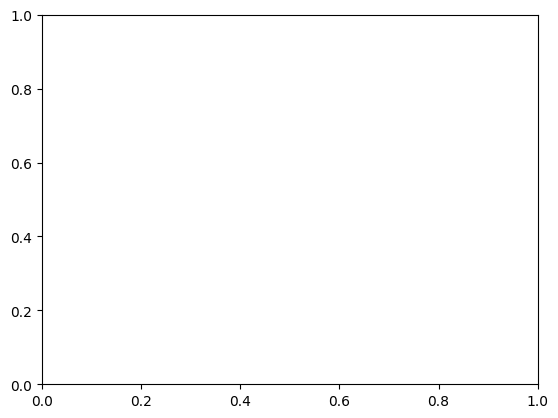

In [43]:
fig,ax=plt.subplots()
xmax = max([v[0] for k,v in pos_xy.items()])
ymax = max([v[1] for k,v in pos_xy.items()])
Graph(G, 
      node_layout={k:(v[0]/xmax,v[1]/ymax) for k,v in pos_xy.items()},
      ax=ax,edge_layout='curved')

In [20]:
print({k:(v[0]/360,v[1]/360) for k,v in pos_lonlat.items()})

{'GIS': (-0.11944444444444445, 0.19444444444444445), 'AMOC': (-0.08333333333333333, 0.11944444444444445), 'ENSO': (-0.3611111111111111, -0.024444444444444446), 'WAIS': (-0.25, -0.20833333333333334), 'ASI': (0.013888888888888888, 0.19444444444444445), 'PERM': (0.2777777777777778, 0.16666666666666666), 'WAM': (0.03888888888888889, 0.05416666666666667), 'REEF': (-0.2222222222222222, 0.03333333333333333), 'AMAZ': (-0.17277777777777778, -0.009722222222222222)}
